<div style="
    background-color: #5B92E5; 
    border-radius: 10px; 
    padding: 20px; 
    border-left: 8px solid #FEC524; 
    border: 2px solid #FEC524;
    text-align: center;
    box-shadow: 3px 3px 10px rgba(0,0,0,0.3);
">
    <h1 style="color: #FEC524; font-family: Arial, sans-serif; margin: 0; text-align: center;">
        🏀 Nikola Jokić: Statistical Investigation
    </h1>
    <p style="color: #FFFFFF; font-size: 16px; margin-top: 10px; text-align: center; font-weight: bold;">
        Analyzing Free Throw Consistency Under Pressure | <span style="color: #0E2240; font-weight: bold;">Denver Nuggets</span>
    </p>
</div>

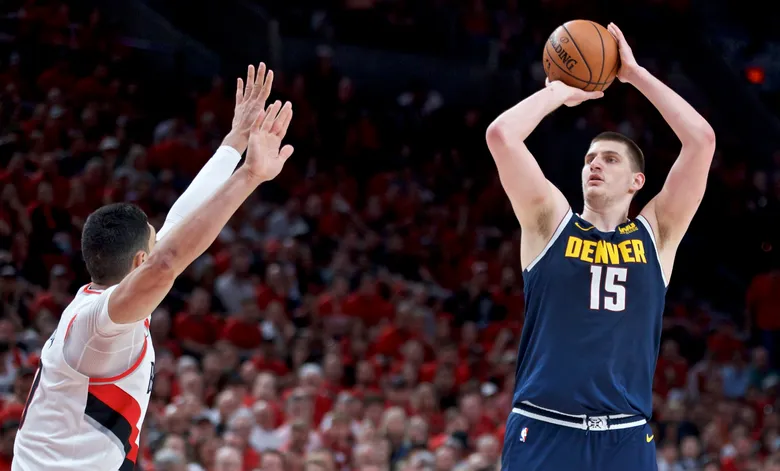

In [25]:
from IPython.display import Image, display
display(Image(filename="Nikola Jokic Picture.webp", width=1000))

<h2 style = "color: #FEC524;"><strong><center>Statistical Investigation Question:</strong></center></h2>

<h3 style = "color: #FEC524;"><center>Assume that Jokic makes 82.5% of his free-throws. What's the probability that he makes at least 8 free-throws in a period of attempting 10 free-throws?</center></h3>

<h2 style = "color: #FEC524;"><strong><center>Type of Simulation:</strong></center></h2>

<h3 style = "color: #FEC524;">1. The random variable (X) is the number of free throws made (0-10). The discrete value it can take is the number of free throws made. Specifically, the first free throw, the second free throw, the third free throw, etc. It ends at the tenth free throw attempt.</h3>

<h3 style = "color: #FEC524;">2. One trial of this simulation is Jokić attempting to make his first free throw. The only two possible outcomes are a make or miss.</h3>

<h2 style = "color: #FEC524;"><strong><center>Simulation Code:</strong></center></h2>

<h3 style = "color: #FEC524;"><strong><center>Theoretical Model Code:</strong></center></h3>

In [26]:
# Import necessary library.
import numpy as np

In [27]:
# Setting a seed makes the "random" generation reproducible.
np.random.seed(42)

In [28]:
# size=100000: Simulates 100,000 games.
# n=10: Sets the number of free-throw attempts per game to 10 (n). 
# p=0.825: Sets the probability of making each individual shot to 82.5%.
simulations = np.random.binomial(n=10, p=0.825, size=100000)
# simulations >= 8: Creates true/false array checking which simulated games resulted in 8, 9, or 10 makes (condition for "delivering in the clutch").
# np.sum(...): Counts how many of the 100,000 games satisfied that condition.
# /100000: Divides total successful games by total number of simulations to calculate the relative freuquency (empirical probability).
prob = np.sum(simulations >= 8) / 100000

In [29]:
# Output will be 75.22% because size is 100,000.
print("Simulated Result: " + str(round(prob * 100, 2)) + "%")

Simulated Result: 75.22%


<h3 style = "color: #FEC524;"><strong><center>Empirical Simulation Code:</strong></center></h3>

In [30]:
# 1. Define investigation parameters.
n_attempts = 10         # Total free throws taken per game.
p_success = 0.825       # Nikola Jokic's career free throw % (according to StatMuse).
num_simulations = 100000 # Number of simulated games.

In [31]:
# 2. Simulate 100,000 games (each with 10 attempts).
simulations = np.random.binomial(n=n_attempts, p=p_success, size=num_simulations)

In [32]:
# 3. Calculate empirical probabilities for all make counts (0 to 10).
makes_counts = np.bincount(simulations, minlength=n_attempts + 1)
simulated_probs = makes_counts / num_simulations

In [33]:
# 4. Display results in clean console output using string concatenation
print("Makes".ljust(10) + " " + "Simulated Probability".ljust(20))
print("-" * 32)
for makes, prob in enumerate(simulated_probs):
    print(str(makes).ljust(10) + " " + str(round(prob * 100, 2)) + "%")

Makes      Simulated Probability
--------------------------------
0          0.0%
1          0.0%
2          0.0%
3          0.03%
4          0.3%
5          1.56%
6          6.26%
7          16.73%
8          29.72%
9          30.94%
10         14.46%


In [34]:
# 5. Answer the core investigation question: P(X >= 8)
at_least_8_makes = np.sum(simulations >= 8)
prob_at_least_8 = at_least_8_makes / num_simulations

In [35]:
print("\n--- Final Results ---")
print("Simulated P(Makes >= 8): " + str(round(prob_at_least_8 * 100, 2)) + "%")


--- Final Results ---
Simulated P(Makes >= 8): 75.11%


In [36]:
# Import necessary libraries.
import math
from scipy.special import comb

In [37]:
# 1. Setup Parameters
n = 10         # Number of free throws taken
p = 0.825      # Nikola Jokić career FT probability (82.5%)
q = 1 - p      # Probability of missing (17.5%)

In [38]:
# 2. Binomial Formula Function: P(X = k) = nCr * p^k * (1-p)^(n-k)
def binomial_pmf(k, n, p):
    nCr = comb(n, k, exact=True)
    return nCr * (p ** k) * ((1 - p) ** (n - k))

In [39]:
# 3. Calculate exact probabilities for every possible make (0 through 10)
print("Makes".ljust(10) + " " + "Exact Probability".ljust(20))
print("-" * 32)

probabilities = {}
for k in range(n + 1):
    prob = binomial_pmf(k, n, p)
    probabilities[k] = prob
    print(str(k).ljust(10) + " " + str(round(prob * 100, 2)) + "%")

# 4. Calculate P(X >= 8) -> Sum of probabilities for k = 8, 9, 10
p_at_least_8 = probabilities[8] + probabilities[9] + probabilities[10]

print("\n--- Final Mathematical Result ---")
print("Theoretical P(Makes >= 8): " + str(round(p_at_least_8 * 100, 2)) + "%")

Makes      Exact Probability   
--------------------------------
0          0.0%
1          0.0%
2          0.0%
3          0.03%
4          0.28%
5          1.58%
6          6.21%
7          16.73%
8          29.57%
9          30.98%
10         14.61%

--- Final Mathematical Result ---
Theoretical P(Makes >= 8): 75.16%


In [40]:
# Import necessary libraries.
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import comb

In [41]:
# 1. Setup Parameters
n = 10         # Attempts per game
p = 0.825      # Jokic's FT percentage
q = 1 - p      # Probability of missing
num_simulations = 10000

In [42]:
# 2. Calculate Theoretical Metrics
mean_theory = n * p
std_theory = np.sqrt(n * p * q)

In [43]:
# 3. Exact Theoretical Binomial Distribution
k_values = np.arange(n + 1)
binom_probs = [comb(n, k, exact=True) * (p**k) * (q**(n-k)) for k in k_values]

In [44]:
# 4. Simulation & Empirical Metrics
np.random.seed(42)
simulations = np.random.binomial(n=n, p=p, size=num_simulations)
sim_counts = np.bincount(simulations, minlength=n + 1)
sim_probs = sim_counts / num_simulations

In [45]:
# Import necessary library.
from scipy.stats import binom

In [46]:
# 1-line theoretical calculation: P(X >= 8) for n=10, p=0.825
theo_prob = binom.sf(7, n=10, p=0.825)

In [47]:
print("Theoretical Result: " + str(round(theo_prob * 100, 2)) + "%")

Theoretical Result: 75.16%


<h2 style = "color: #FEC524;"><strong><center>Conclusion:</strong></center></h2>

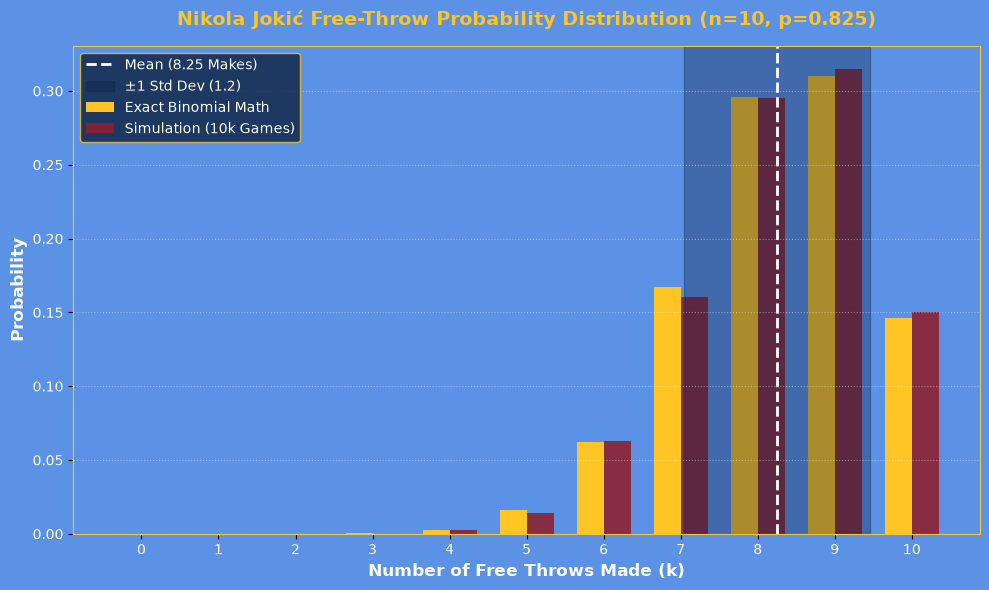

In [48]:
# 5. Plotting the Graph with Classic Nuggets Light Blue Background
plt.figure(figsize=(10, 6), facecolor='#5B92E5')
ax = plt.axes()
ax.set_facecolor('#5B92E5')

# Bar Plot: Exact Math vs. Simulation
bar_width = 0.35
plt.bar(k_values - bar_width/2, binom_probs, width=bar_width, label='Exact Binomial Math', color='#FEC524')
plt.bar(k_values + bar_width/2, sim_probs, width=bar_width, label='Simulation (10k Games)', color='#8B2131', alpha=0.9)

# Add Mean and Standard Deviation Reference Lines
plt.axvline(mean_theory, color='#FFFFFF', linestyle='--', linewidth=2, 
            label='Mean (' + str(round(mean_theory, 2)) + ' Makes)')
plt.axvspan(mean_theory - std_theory, mean_theory + std_theory, color='#0E2240', alpha=0.35, 
            label='±1 Std Dev (' + str(round(std_theory, 2)) + ')')

# Formatting Chart Aesthetics
plt.title('Nikola Jokić Free-Throw Probability Distribution (n=10, p=0.825)', color='#FEC524', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Number of Free Throws Made (k)', color='#FFFFFF', fontsize=12, fontweight='bold')
plt.ylabel('Probability', color='#FFFFFF', fontsize=12, fontweight='bold')
plt.xticks(k_values, color='#FFFFFF')
plt.yticks(color='#FFFFFF')
plt.grid(axis='y', linestyle=':', alpha=0.4, color='#FFFFFF')

# Legend Styling
legend = plt.legend(facecolor='#0E2240', edgecolor='#FEC524', fontsize=10)
for text in legend.get_texts():
    text.set_color('#FFFFFF')

# Adjust border colors
for spine in ax.spines.values():
    spine.set_color('#FEC524')

plt.tight_layout()
plt.show()

<h3 style = "color: #FEC524;"><center>In conclusion, the theoretical and empirical probabilities of Jokic making at least 8 free throws are approximately 75.16% and 75.11%, respectively. The simulation ran for a grand total of 10,000 times. In this case, the mean is 8.25 makes, which can be rounded down to 8 made free throws. According to the graph, we can see that Jokic has a really high chance, especially in the last couple of free throws, to make at least 8 of them. The standard deviation signifies that the standard deviation is 1.2 standard deviations above AND below the mean.</center></h3>

In [50]:
from IPython.display import HTML, display

classic_nuggets_blue_css = """
<script>
    var style = document.createElement('style');
    style.innerHTML = `
        body, .jp-Notebook, div#notebook-container {
            background-color: #418FDE !important;
        }
        .jp-Cell, div.cell {
            background-color: #5B92E5 !important;
            border-radius: 8px;
            margin-bottom: 10px;
        }
    `;
    document.head.appendChild(style);
</script>
"""
display(HTML(classic_nuggets_blue_css))